# EduForest · Análisis exploratorio del SIAGIE 2021-2024

**Curso:** CC65 Programación Concurrente y Distribuida (UPC) · **Entregable:** PC3

**Dataset:** *Matriculación y Trayectoria Estudiantil 2021-2024* (MINEDU, Unidad de Estadística), descargado de [datosabiertos.gob.pe](https://www.datosabiertos.gob.pe/dataset/matriculaci%C3%B3n-y-trayectoria-estudiantil-2021-2024). Son 4 CSV, uno por año. Cada fila es un **servicio educativo** (código modular + anexo + nivel) desagregado por **edad** y **tipo de discapacidad**, con conteos de alumnos: aprobados, desaprobados, retirados, con atraso escolar, etc.

**Objetivo de este notebook:** entender los datos antes de modelar, justificar cada decisión de limpieza y definir las dos variables objetivo (nivel de logro y riesgo de deserción).

> La limpieza oficial del proyecto corre en Go, de forma concurrente (`go/internal/dataset`). Aquí se usa pandas solo para explorar y para comprobar que ambos dan los mismos números.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

DATA = Path("../data/siagie")
FIGS = Path("../docs/PC3/figuras")
FIGS.mkdir(parents=True, exist_ok=True)
YEARS = [2021, 2022, 2023, 2024]

# Estilo común de los gráficos del informe
BLUE, ORANGE, INK, INK2, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
mpl.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "legend.frameon": False, "savefig.dpi": 220, "savefig.bbox": "tight", "lines.linewidth": 2,
})
pct_axis = lambda axis: axis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=1))

## 1. Carga y estructura

Las cabeceras no son iguales todos los años: en 2021-2022 la columna de alumnos que no aprobaron se llama `PromocionGuiada` (la promoción guiada fue la medida del MINEDU por la pandemia) y en 2023-2024 se llama `Desaprobado`. Se unifican en una sola columna, `NoAprobado`.

In [2]:
frames = []
for y in YEARS:
    df = pd.read_csv(DATA / f"siagie_matricula_{y}.csv", low_memory=False)
    col = "Desaprobado" if "Desaprobado" in df.columns else "PromocionGuiada"
    print(f"{y}: {len(df):>8,} filas · {df.shape[1]} columnas · columna de no aprobados: {col}")
    frames.append(df.rename(columns={col: "NoAprobado"}).assign(anio=y))
raw = pd.concat(frames, ignore_index=True)
print(f"\nTotal: {len(raw):,} filas")
raw.head()

2021:  566,359 filas · 26 columnas · columna de no aprobados: PromocionGuiada


2022:  558,785 filas · 26 columnas · columna de no aprobados: PromocionGuiada


2023:  544,834 filas · 26 columnas · columna de no aprobados: Desaprobado


2024:  535,137 filas · 26 columnas · columna de no aprobados: Desaprobado

Total: 2,205,115 filas


,cod_mod,anexo,Nombre,gestion,id_nivel,dsc_nivel,Edad,TipoDiscaIntegrada,TotalEstudiantes,Discapacidad,...,No_DNI,Aprobado,NoAprobado,Retirado,Fallecido,RequiereRecuperacion,Matriculado,PostergaEvaluacion,tot_atraso,anio
0,1506,0,LOS LUCEROS,Pública de gestión directa,A5,Inicial no escolarizado,4.0,NaN,2,0,...,0,2,0,0,0,0,0,0,0,2021
1,1506,0,LOS LUCEROS,Pública de gestión directa,A5,Inicial no escolarizado,5.0,NaN,1,0,...,0,1,0,0,0,0,0,0,0,2021
2,1507,0,EL NUEVO AMANECER,Pública de gestión directa,A5,Inicial no escolarizado,3.0,NaN,1,0,...,0,1,0,0,0,0,0,0,0,2021
3,1507,0,EL NUEVO AMANECER,Pública de gestión directa,A5,Inicial no escolarizado,4.0,NaN,3,0,...,0,3,0,0,0,0,0,0,0,2021
4,1507,0,EL NUEVO AMANECER,Pública de gestión directa,A5,Inicial no escolarizado,5.0,NaN,4,0,...,0,4,0,0,0,0,0,0,0,2021


In [3]:
# Nulos, duplicados y tipos
nulos = raw.isna().mean().loc[lambda s: s > 0]
print("Columnas con nulos:\n", (nulos * 100).round(1).astype(str) + "%")
key = ["anio", "cod_mod", "anexo", "id_nivel", "Edad", "TipoDiscaIntegrada"]
print("\nFilas duplicadas exactas:", raw.duplicated().sum())
print("Claves repetidas (año, colegio, nivel, edad, discapacidad):", raw.duplicated(key).sum())

Columnas con nulos:
 Edad                   0.0%
TipoDiscaIntegrada    88.0%
dtype: str



Filas duplicadas exactas: 0


Claves repetidas (año, colegio, nivel, edad, discapacidad): 0


`TipoDiscaIntegrada` vacío no es un dato faltante: significa que el grupo no tiene una discapacidad registrada. Por eso no se imputa; se convierte en la variable binaria `tipo_disca_registrado`. No hay duplicados.

## 2. Consistencia de los conteos

Cada alumno debe tener exactamente una situación final, y el desglose por sexo debe sumar el total.

In [4]:
situaciones = ["Aprobado", "NoAprobado", "Retirado", "Fallecido", "RequiereRecuperacion", "Matriculado", "PostergaEvaluacion"]
raw["Base"] = raw.TotalEstudiantes - raw.Fallecido
raw["consistente"] = (
    (raw.TotalEstudiantes > 0) & (raw.Base > 0)
    & (raw[situaciones].sum(axis=1) == raw.TotalEstudiantes)
    & (raw.Mujer + raw.Hombre == raw.TotalEstudiantes)
)
print(f"Filas inconsistentes: {(~raw.consistente).sum():,} de {len(raw):,} ({(~raw.consistente).mean():.4%})")
print(f"De ellas, en Primaria y Secundaria: {(raw.dsc_nivel.isin(['Primaria', 'Secundaria']) & ~raw.consistente).sum():,}")

Filas inconsistentes: 365 de 2,205,115 (0.0166%)
De ellas, en Primaria y Secundaria: 326


## 3. Nivel educativo

Inicial no tiene calificaciones (todos sus alumnos figuran como aprobados), así que no aporta al nivel de logro. El análisis y el modelo se centran en **Primaria y Secundaria**.

In [5]:
por_nivel = raw.groupby("dsc_nivel").agg(filas=("cod_mod", "size"), alumnos=("TotalEstudiantes", "sum"),
                                         no_aprobados=("NoAprobado", "sum"))
por_nivel.sort_values("filas", ascending=False)

,filas,alumnos,no_aprobados
dsc_nivel,,,
Primaria,1095268,14921367,271076
Secundaria,498377,11245055,756274
Inicial - Jardín,404845,5349065,55529
Inicial no escolarizado,174050,642319,8234
Inicial - Cuna-Jardín,32343,692583,9458
Inicial - Cuna,232,3967,139


In [6]:
escolar = raw[raw.dsc_nivel.isin(["Primaria", "Secundaria"]) & raw.consistente].copy()
escolar["NoLogro"] = escolar.NoAprobado + escolar.RequiereRecuperacion
tasas = escolar.groupby(["anio", "dsc_nivel"])[["Base", "Retirado", "NoLogro"]].sum()
tasas["tasa_retiro"] = tasas.Retirado / tasas.Base
tasas["tasa_no_logro"] = tasas.NoLogro / tasas.Base
tasas.round(4)

Base  Retirado  NoLogro  tasa_retiro  tasa_no_logro
anio dsc_nivel                                                         
2021 Primaria    3776364      4934    68441       0.0013         0.0181
     Secundaria  2729832      4711   302457       0.0017         0.1108
2022 Primaria    3769459     10108    39278       0.0027         0.0104
     Secundaria  2788720     15034   171230       0.0054         0.0614
2023 Primaria    3721133     20392    91222       0.0055         0.0245
     Secundaria  2841864     39694   164524       0.0140         0.0579
2024 Primaria    3651915     13031    80842       0.0036         0.0221
     Secundaria  2881542     30975   189970       0.0107         0.0659

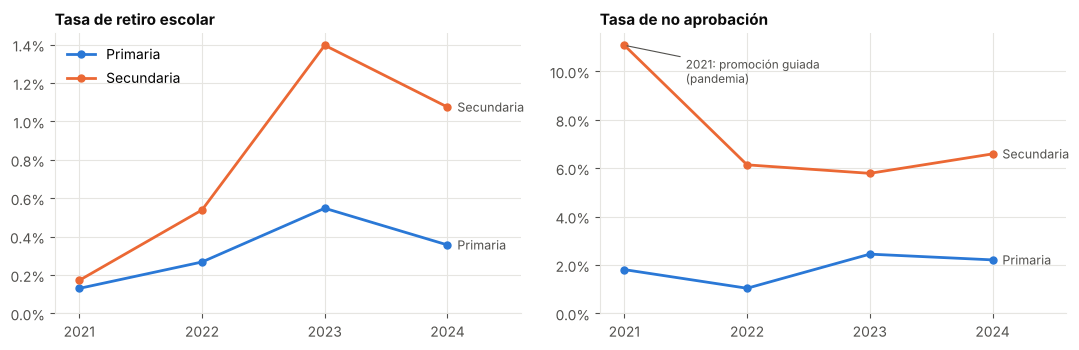

In [7]:
t = tasas.reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in [(axs[0], "tasa_retiro", "Tasa de retiro escolar"), (axs[1], "tasa_no_logro", "Tasa de no aprobación")]:
    for nivel, color in [("Primaria", BLUE), ("Secundaria", ORANGE)]:
        d = t[t.dsc_nivel == nivel]
        ax.plot(d.anio, d[col], color=color, marker="o", ms=5, label=nivel)
        ax.text(2024.08, d[col].iloc[-1], nivel, color=INK2, va="center", fontsize=9)
    ax.set_xticks(YEARS); ax.set_xlim(2020.8, 2024.6); ax.set_ylim(bottom=0); ax.set_title(title); pct_axis(ax.yaxis)
axs[0].legend(loc="upper left")
pico = t[(t.anio == 2021) & (t.dsc_nivel == "Secundaria")].tasa_no_logro.iloc[0]
axs[1].annotate("2021: promoción guiada\n(pandemia)", (2021, pico), (2021.5, pico * 0.86), fontsize=8.5, color=INK2,
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
fig.tight_layout(); fig.savefig(FIGS / "fig_eda_tasas_anio.png"); plt.show()

**Hallazgos:**
- El retiro escolar en **secundaria** subió de 0.17% en 2021 a 1.40% en 2023 y en 2024 se mantiene en 1.07%, el triple que en primaria. El retiro se concentra en secundaria.
- La no aprobación de 2021 (11% en secundaria) está inflada por la promoción guiada de la pandemia. Desde 2022 se estabiliza alrededor de 6% en secundaria y 2% en primaria.

## 4. Tipo de gestión

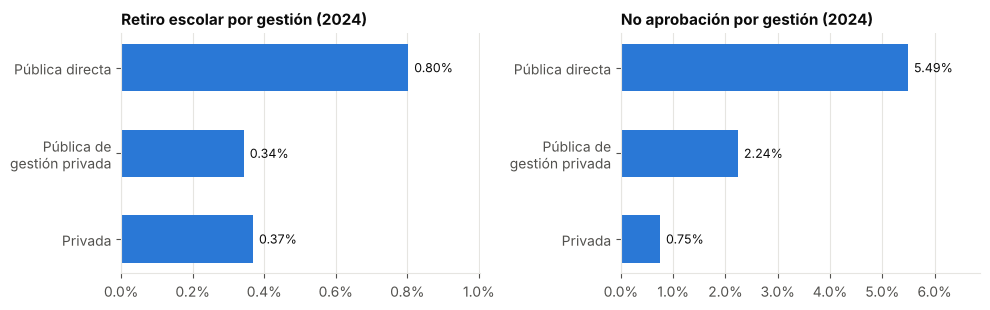

,tasa_retiro,tasa_no_logro
gestion,,
Pública de gestión directa,0.0080,0.0549
Pública de gestión privada,0.0034,0.0224
Privada,0.0037,0.0075


In [8]:
g = escolar[escolar.anio == 2024].groupby("gestion")[["Base", "Retirado", "NoLogro"]].sum()
g = g.loc[["Pública de gestión directa", "Pública de gestión privada", "Privada"]]
g["tasa_retiro"] = g.Retirado / g.Base
g["tasa_no_logro"] = g.NoLogro / g.Base
etiquetas = ["Pública directa", "Pública de\ngestión privada", "Privada"]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, title in [(axs[0], "tasa_retiro", "Retiro escolar por gestión (2024)"), (axs[1], "tasa_no_logro", "No aprobación por gestión (2024)")]:
    bars = ax.barh(etiquetas, g[col], color=BLUE, height=0.55)
    ax.invert_yaxis(); ax.grid(axis="y", visible=False); pct_axis(ax.xaxis); ax.set_title(title)
    ax.set_xlim(0, g[col].max() * 1.25)
    for b, v in zip(bars, g[col]):
        ax.text(v + g[col].max() * 0.02, b.get_y() + b.get_height() / 2, f"{v:.2%}", va="center", color=INK, fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "fig_eda_gestion.png"); plt.show()
g[["tasa_retiro", "tasa_no_logro"]].round(4)

En los colegios **públicos de gestión directa** el retiro (0.80%) duplica al de los privados (0.37%) y la no aprobación es 7 veces mayor. La gestión entra como feature del modelo.

## 5. Tamaño de los grupos

Las tasas se calculan por grupo (colegio × edad × discapacidad). En un grupo de 1 o 2 alumnos la tasa solo puede ser 0%, 50% o 100%: es ruido, no información.

In [9]:
tam = escolar.TotalEstudiantes
print(f"Mediana de alumnos por grupo: {tam.median():.0f}")
for m in [2, 3, 5, 10]:
    print(f"Grupos con < {m:>2} alumnos: {(tam < m).mean():6.1%}   muestras que quedan con >= {m}: {(tam >= m).sum():>9,}")

Mediana de alumnos por grupo: 5
Grupos con <  2 alumnos:  25.9%   muestras que quedan con >= 2: 1,180,504
Grupos con <  3 alumnos:  35.9%   muestras que quedan con >= 3: 1,021,419
Grupos con <  5 alumnos:  48.0%   muestras que quedan con >= 5:   827,764
Grupos con < 10 alumnos:  64.3%   muestras que quedan con >= 10:   569,569


Con un mínimo de **3 alumnos** se descartan los grupos más ruidosos y todavía quedan **más de 1 millón de muestras**, el volumen que exige el trabajo.

## 6. Resumen de la limpieza

Estos números deben coincidir exactamente con los que imprime el loader en Go (`go run ./cmd/loader`).

Filas leídas (4 CSV)            2,205,115
Inicial (sin calificaciones)      611,470
Conteos inconsistentes                326
Grupos con < 3 alumnos            571,900
Muestras finales                1,021,419


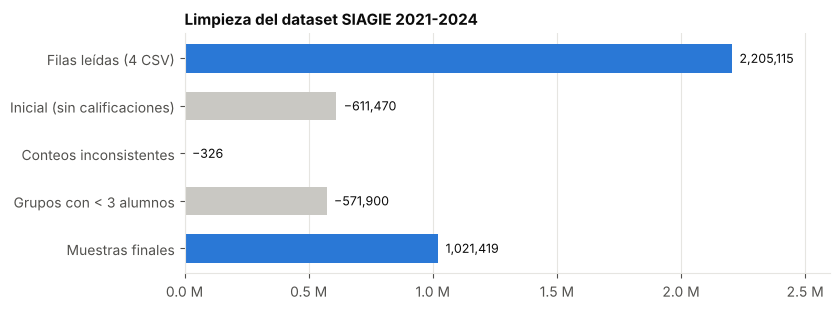

In [10]:
pasos = {
    "Filas leídas (4 CSV)": len(raw),
    "Inicial (sin calificaciones)": (~raw.dsc_nivel.isin(["Primaria", "Secundaria"])).sum(),
    "Conteos inconsistentes": (raw.dsc_nivel.isin(["Primaria", "Secundaria"]) & ~raw.consistente).sum(),
    "Grupos con < 3 alumnos": (escolar.TotalEstudiantes < 3).sum(),
}
muestras = escolar[escolar.TotalEstudiantes >= 3].copy()
pasos["Muestras finales"] = len(muestras)
for k, v in pasos.items():
    print(f"{k:<30} {v:>10,}")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
ys = list(range(len(pasos)))[::-1]
for yi, (lab, v) in zip(ys, pasos.items()):
    descarte = lab not in ("Filas leídas (4 CSV)", "Muestras finales")
    ax.barh(yi, v, color="#c9c8c3" if descarte else BLUE, height=0.6)
    ax.text(v + 30000, yi, ("−" if descarte else "") + f"{v:,}", va="center", color=INK, fontsize=9)
ax.set_yticks(ys, list(pasos)); ax.grid(axis="y", visible=False); ax.set_xlim(0, 2.6e6)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"{v/1e6:.1f} M"))
ax.set_title("Limpieza del dataset SIAGIE 2021-2024")
fig.tight_layout(); fig.savefig(FIGS / "fig_limpieza.png"); plt.show()

## 7. Variables objetivo

Se definen dos clasificaciones de 3 clases por grupo:

| Objetivo | Tasa | Clases |
|---|---|---|
| **Nivel de logro** | (no aprobados + requieren recuperación) / alumnos | alto: 0% · medio: hasta 20% · bajo: más de 20% |
| **Riesgo de deserción** | retirados / alumnos | bajo: 0% · medio: hasta 10% · alto: más de 10% |

Los umbrales salen de la distribución. Entre los grupos que tienen algún no aprobado, la mediana de la tasa es 11% y el percentil 75 es 24%: 20% separa los casos moderados de los graves. En el retiro, 10% queda cerca del percentil 90 de los colegios que tienen algún retirado.

No aprobación > 0, percentiles: {0.5: 0.111, 0.75: 0.24, 0.9: 0.385}


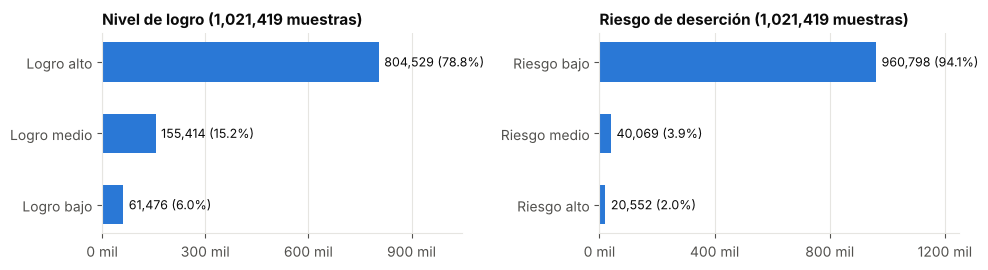

In [11]:
muestras["tasa_no_logro"] = muestras.NoLogro / muestras.Base
muestras["tasa_retiro"] = muestras.Retirado / muestras.Base
print("No aprobación > 0, percentiles:", muestras.tasa_no_logro[muestras.tasa_no_logro > 0].quantile([.5, .75, .9]).round(3).to_dict())

def clase(tasa, umbral):
    return pd.cut(tasa, [-1, 0, umbral, 1], labels=[0, 1, 2]).astype(int)

muestras["clase_logro"] = clase(muestras.tasa_no_logro, 0.20)
muestras["clase_riesgo"] = clase(muestras.tasa_retiro, 0.10)

fig, axs = plt.subplots(1, 2, figsize=(10, 2.8))
for ax, col, names, title in [
    (axs[0], "clase_logro", ["Logro alto", "Logro medio", "Logro bajo"], "Nivel de logro"),
    (axs[1], "clase_riesgo", ["Riesgo bajo", "Riesgo medio", "Riesgo alto"], "Riesgo de deserción"),
]:
    vals = muestras[col].value_counts().sort_index().values
    bars = ax.barh(names, vals, color=BLUE, height=0.55); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_title(f"{title} ({len(muestras):,} muestras)"); ax.set_xlim(0, vals.max() * 1.3)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"{v/1000:.0f} mil"))
    for b, v in zip(bars, vals):
        ax.text(v + vals.max() * 0.02, b.get_y() + b.get_height() / 2, f"{v:,} ({v/vals.sum():.1%})", va="center", color=INK, fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "fig_clases.png"); plt.show()

Las dos variables están **desbalanceadas**, sobre todo el riesgo (94% de riesgo bajo). Un modelo que siempre respondiera "riesgo bajo" tendría 94% de exactitud y no serviría para nada. Por eso el Random Forest usa un **bootstrap balanceado** (parámetro `-balance`) y se evalúa con recall por clase, F1 macro y exactitud balanceada, no solo con exactitud.

## 8. Conclusiones del EDA

1. El dataset está limpio en estructura (sin duplicados y con solo 326 filas inconsistentes), pero cambia de esquema entre años y hay que unificarlo.
2. El retiro escolar se concentra en **secundaria** y en colegios **públicos de gestión directa**, y creció tras la pandemia.
3. Filtrar Inicial y los grupos de menos de 3 alumnos deja **1,021,419 muestras** con tasas confiables.
4. El fuerte desbalance de clases condiciona el entrenamiento y la forma de evaluar el modelo.